In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:

df = pd.read_csv('/content/drive/MyDrive/data_frame/cars.csv')

In [3]:
df.shape

(4023, 12)

In [4]:
df.dtypes

,0
brand,object
model,object
model_year,int64
milage,int64
fuel_type,object
engine,object
transmission,object
ext_col,object
int_col,object
accident,object


In [5]:
df.duplicated().sum()

np.int64(14)

In [6]:
df.isnull().sum()

,0
brand,0
model,0
model_year,0
milage,0
fuel_type,170
engine,0
transmission,0
ext_col,0
int_col,0
accident,114


<div dir="ltr">

### Data Quality Assessment

The dataset includes 4,023 rows and 12 columns. There are three numerical columns (model_year, milage, price) and nine text columns. 14 completely duplicate rows were identified. Four columns have missing values:
clean_title with 598 cases, fuel_type with 170 cases, accident with 114 cases, and price with 28 cases.


**What are the most important problems in this dataset?**

The most important problems are the presence of 14 duplicate records, significant missing values in four columns, especially clean_title, and structural inconsistency in the engine column, which will be examined in the following tasks.


</div>

In [7]:
print("Duplicates before:", df.duplicated().sum())

Duplicates before: 14


In [8]:
df = df.drop_duplicates()
print("New shape after removing duplicates:", df.shape)

New shape after removing duplicates: (4009, 12)


<div dir="ltr">

### Duplicate Data Management

14 completely duplicate records, with identical values across all 12 columns, were identified and removed. The shape of the dataset decreased from 4023 to 4009 rows. The reason for removing them is that the presence of duplicate records causes the model to give more weight to that particular pattern, and this can lead to bias in the model's learning.

</div>

In [9]:
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent[missing_percent > 0]

,0
fuel_type,4.240459
accident,2.818658
clean_title,14.866550
price,0.698429


In [10]:
df['fuel_type'] = df['fuel_type'].fillna(df['fuel_type'].mode()[0])

In [11]:
df['accident'] = df['accident'].fillna(df['accident'].mode()[0])

In [12]:
df['clean_title'] = df['clean_title'].fillna('Unknown')

In [13]:
df = df.dropna(subset=['price'])

In [14]:
df.isnull().sum()

,0
brand,0
model,0
model_year,0
milage,0
fuel_type,0
engine,0
transmission,0
ext_col,0
int_col,0
accident,0


<div dir="ltr">

### Missing Data Management

The decision for each column was made based on the percentage of missing values and the nature of the column. For fuel_type (about 4% missing) and accident (about 3% missing), the most frequent value was used for imputation because the percentage of missing values is low and this method does not disrupt the data.

For clean_title, which had a high percentage of missing values (about 15%), instead of filling it with the dominant value, which could have caused bias, a new category called Unknown was created so that this uncertainty would remain honestly recorded in the data.

For the price column, since it is the target variable of the project, rows with missing values were removed because there is no valid replacement for them, and the model should be trained on actual prices.

</div>

In [15]:
df['engine'].unique()[:20]

array(['300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability',
       '3.8L V6 24V GDI DOHC', '3.5 Liter DOHC',
       '354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid',
       '2.0L I4 16V GDI DOHC Turbo', '2.4 Liter',
       '292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel',
       '282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel',
       '311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel',
       '534.0HP Electric Motor Electric Fuel System', 'V6',
       '715.0HP 5.2L 12 Cylinder Engine Gasoline Fuel',
       '382.0HP 3.0L Straight 6 Cylinder Engine Gasoline Fuel',
       '400.0HP 3.0L V6 Cylinder Engine Gasoline Fuel',
       '2.0 Liter Supercharged',
       '375.0HP 5.0L 8 Cylinder Engine Gasoline Fuel',
       '305.0HP 3.6L V6 Cylinder Engine Gasoline Fuel',
       '287.0HP 3.5L V6 Cylinder Engine Gasoline Fuel',
       '550.0HP 5.0L 8 Cylinder Engine Gasoline Fuel',
       '375.0HP 3.5L V6 Cylinder Engine Gasoline Fuel'], dtype=object)

In [16]:
df['engine'].sample(10, random_state=1)

,engine
189,455.0HP Electric Motor Electric Fuel System
1394,335.0HP 3.0L Straight 6 Cylinder Engine Gasoli...
1565,333.0HP 3.2L Straight 6 Cylinder Engine Gasoli...
370,323.0HP 6.0L 8 Cylinder Engine Gasoline Fuel
2366,3.5L V6 24V PDI DOHC
809,155.0HP 2.0L 4 Cylinder Engine Gasoline Fuel
905,463.0HP 4.0L 8 Cylinder Engine Gasoline Fuel
1110,179.0HP 2.5L 4 Cylinder Engine Gasoline Fuel
3577,270.0HP 4.7L 8 Cylinder Engine Gasoline Fuel
2323,272.0HP 3.5L V6 Cylinder Engine Gasoline Fuel


<div dir="ltr">

### Engine Column Analysis

**Is all the data in the same structure?**

No. This column has at least three different patterns: a complete format including engine power, engine displacement, and cylinder type, incomplete formats that contain only some of this information, and very short values such as V6 that only indicate the cylinder type. Electric engines also have a completely different structure.

**What information is contained in this column?**

This column is a combined text string that contains up to four types of information: engine power in horsepower, engine displacement in liters, the number or type of cylinders, and the type of fuel system.

**What features can be extracted from this column?**

In later phases, separate columns can be created for engine power, engine displacement, number of cylinders, and Boolean flags such as whether the engine is turbocharged or electric. This requires text processing with Regular Expressions and will not be performed in this phase.

</div>

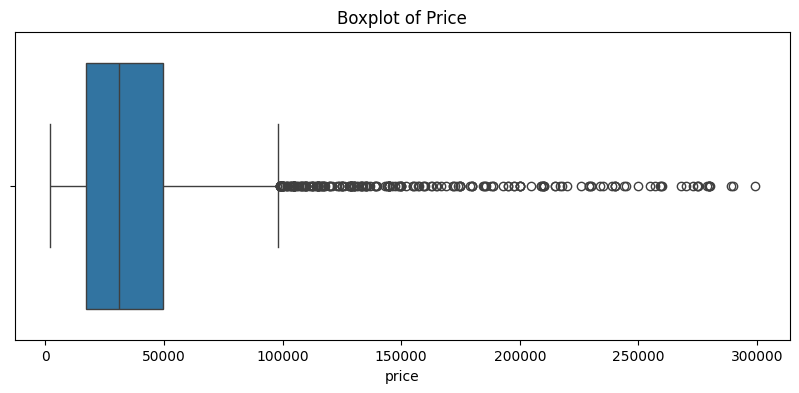

In [17]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price'])
plt.title('Boxplot of Price')
plt.show()

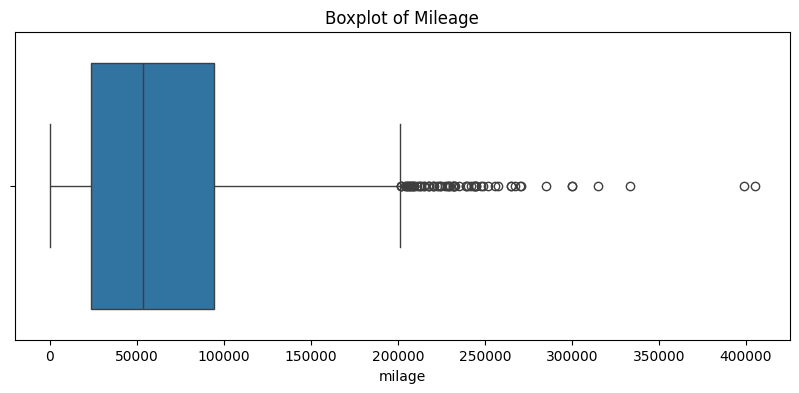

In [18]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['milage'])
plt.title('Boxplot of Mileage')
plt.show()

<div dir="ltr">

### Outlier Data Analysis

**Are there any outliers?**

Yes, a significant number of outliers can be observed in both the price and milage columns. In the price column, the normal range extends to around one hundred thousand dollars, and after that, many points up to three hundred thousand dollars are seen as outliers. In the milage column, the normal range extends to around two hundred thousand miles, and after that, scattered points appear up to four hundred thousand miles.

**Is it reasonable to remove them?**

No, completely removing these data points is not recommended. These outliers mostly represent real and acceptable vehicles, such as luxury cars or older vehicles with very high mileage, rather than data entry errors. Removing them would eliminate valuable information from the dataset. Instead of removing them, it would be better to use logarithmic transformation or models that are resistant to outliers during the modeling phase.

</div>

In [19]:
df.dtypes

,0
brand,object
model,object
model_year,int64
milage,int64
fuel_type,object
engine,object
transmission,object
ext_col,object
int_col,object
accident,object


<div dir="ltr">

### Data Type Analysis

The current data types are appropriate. The `model_year` and `milage` columns are correctly stored as `int64`, and the `price` column is correctly stored as `float64`. Text columns such as `brand`, `model`, `fuel_type`, `transmission`, `ext_col`, `int_col`, `accident`, and `clean_title` are also correctly stored as `object`, since they all contain categorical or descriptive data.

The only exception is the `engine` column. Although its current `object` data type is not problematic, this column is a combination of several numerical and categorical pieces of information. In later phases, after feature extraction, it should be transformed into multiple columns with appropriate data types. At this stage, there is no need to change the data type of any column.

</div>

In [20]:
print("Negative prices:", (df['price'] < 0).sum())

print("Negative mileage:", (df['milage'] < 0).sum())

print("Unrealistic years:", df[(df['model_year'] < 1900) | (df['model_year'] > 2026)].shape[0])

Negative prices: 0
Negative mileage: 0
Unrealistic years: 0


<div dir="ltr">

### Data Consistency Analysis

The analysis of the three main cases showed that this dataset has no consistency issues. There are no negative values in the `price` column, no negative values in the `milage` column, and no unreasonable manufacturing years (less than 1900 or greater than 2026) were found. Therefore, the data is reliable in terms of the logical consistency of numerical values.

</div>

In [21]:
os.makedirs('data', exist_ok=True)
df.to_csv('data/cars_clean.csv', index=False)
print("Saved successfully. Final shape:", df.shape)

Saved successfully. Final shape: (3981, 12)


<div dir="ltr">

### Final Dataset Saving

After completing all the cleaning steps, the final dataset with 3981 rows and 12 columns was saved under the name `cars_clean.csv`. This file is separate from the original `cars.csv` file, and the raw file remains untouched.

</div>